<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Explorative Datenanalyse

---
TODO:
- Code, Logik und Dokuementation erweitern auf mehrtägige Analyse --> auch warum man die Tage trennt (intraday)
- durch die Erweiterung entstehenden neuen Fragen klären --> Wer ist ein konsistentes Paar? Gibtes Trends? usw.
- Einwände von Herr Würsch übernehmen
- Struktur dieses Dokuments überarbeiten, weil es unübersichtlich ist --> evt. gesamte Theorie in Einleitung? EDA aufteilen (eher nicht, ausser Code wird zu langsam)?
- Inhaltsverzeichnis auf der Seite der HTML-Seite möglich?
- Können die HTML-Exports in einen separaten Ordner gemacht werden ohne Einschränkungen?
- Macht man ein neues CSV-Dokument für die Daten der gewählten Paare?
---

In diesem Abschnitt wird die Datenbasis für das Pairs-Trading-Projekt systematisch untersucht. Ziel der explorativen Datenanalyse (EDA) ist es, ein Verständnis für die Struktur, Qualität und statistischen Eigenschaften der Kursdaten zu gewinnen, bevor darauf aufbauend Modelle für das maschinelle Lernen entwickelt werden.

Die analysierten Daten bestehen aus hochfrequenten Kurszeitreihen des S&P 500 mit einer zeitlichen Auflösung von einer Minute (Dateien: `sp500_1min_YYYY-MM-DD.csv`). Jede Zeile repräsentiert den Kurs eines bestimmten Wertpapiers zu einem gegebenen Zeitpunkt.

Das Vorgehen in diesem Kapitel gliedert sich in mehrere Schritte:

1. **Datenüberblick und Datenqualität**  
   Laden des Datensatzes, erste Kennzahlen (Anzahl Zeilen, Anzahl Ticker) und Prüfung auf fehlende Werte.
   Datensatz inspizieren, Datenlücken analyysieren und Datensatz säubern

3. **Untersuchung von Beziehungen zwischen Aktien**  
   Berechnung von Korrelationen zwischen Kursreihen und Darstellung stark korrelierter Aktienbeziehungen in Form eines Netzwerks.

2. **Fazit**
   


## 3.1. Theoretische Grundlage

Das Pairs Trading basiert auf der Annahme, dass sich die Kurse zweier stark miteinander verbundener Wertpapiere langfristig in einem stabilen Verhältnis bewegen.  
Wenn dieses Gleichgewicht vorübergehend gestört wird, eröffnet sich eine potenzielle Arbitragemöglichkeit: man geht in die unterbewertete Aktie **long** und in die überbewertete **short**, in Erwartung einer Rückkehr zum Mittelwert.

Damit diese Strategie fundiert umgesetzt werden kann, müssen drei zentrale Konzepte verstanden und überprüft werden.

### Korrelation

Die lineare Korrelation beschreibt, inwieweit sich zwei Zeitreihen gemeinsam bewegen.  
Sie wird durch den **Pearson-Korrelationskoeffizienten** $\rho_{X,Y}$ berechnet:

$$
\rho_{X,Y} = \frac{\mathrm{Cov}(X_t, Y_t)}{\sigma_X \cdot \sigma_Y}
$$

Ein Wert von $\rho_{X,Y} = 1$ bedeutet eine perfekte positive lineare Beziehung, während $\rho_{X,Y} = 0$ auf keinen linearen Zusammenhang hinweist.  
Im Rahmen des Pairs Trading deutet eine hohe Korrelation auf **ähnliches kurzfristiges Preisverhalten** hin – sie allein garantiert jedoch **keine langfristige Stabilität** der Beziehung.

### Cointegration

Zwei Preisreihen können stark korreliert sein, ohne eine langfristige Gleichgewichtsbeziehung zu besitzen.  
Die **Cointegration** erweitert das Konzept der Korrelation, indem sie prüft, ob eine lineare Kombination zweier nicht-stationärer Zeitreihen stationär ist.  
Formell gilt:

$$
Y_t = \alpha + \beta X_t + \varepsilon_t, \quad \varepsilon_t \sim I(0)
$$

Wenn der Fehlerterm $\varepsilon_t$ stationär ist, bedeutet dies, dass die beiden Reihen $X_t$ und $\ Y_t$ **gemeinsam einem langfristigen Gleichgewicht** folgen.  
Dies ist die theoretische Grundlage für die Berechnung des sogenannten **Spreads** im Pairs Trading.

### Stationarität und Z-Score

Der Spread $S_t = Y_t - \beta X_t$ beschreibt die Abweichung einer Aktie von der linearen Beziehung zur anderen.  
Damit eine Mean-Reversion-Strategie sinnvoll ist, muss der Spread stationär sein – das heißt, er schwankt um einen stabilen Mittelwert.

Um die Stärke der Abweichung zu messen, wird der Spread meist standardisiert:

$$
Z_t = \frac{S_t - \mu_S}{\sigma_S}
$$

Ein hoher Z-Score (z. B. > 2) deutet auf eine Überbewertung (Short-Signal), ein niedriger Z-Score (z. B. < −2) auf eine Unterbewertung (Long-Signal) hin.  
Die Analyse von Korrelation, Cointegration und Z-Score bildet daher die theoretische Basis, um **Paare mit stabiler, mean-revertierender Beziehung** zu identifizieren.

## 3.2. Datenqualität

### 3.2.1. Überblick
Bevor statistische Analysen oder Modellierungen durchgeführt werden, muss ein grundlegendes Verständnis des verwendeten Datensatzes geschaffen werden.  
In diesem Abschnitt werden Struktur, Umfang und Qualität der zugrunde liegenden Kursdaten untersucht.

Die verwendeten Daten bestehen aus hochfrequenten 1-Minuten-Preisen der im S&P 500 enthaltenen Aktien. Der rohe Datensatz umfasst Kurse vom **07. November 2025** bis zum **DATUM NOCH NICHT DEFINIERT** und enthält insgesamt mehrere millionen Zeilen.  
Jede Zeile repräsentiert den Preis eines bestimmten Wertpapiers zu einem bestimmten Zeitpunkt (`datetime`).

Zunächst werden grundlegende Kennzahlen wie die Anzahl der Zeilen und der enthaltenen Ticker (Symbole) ermittelt. Anschließend erfolgt eine Prüfung auf fehlende Werte, um Datenlücken oder Unstimmigkeiten im Datensatz zu identifizieren.

Diese Analyse dient als Grundlage für alle weiteren Schritte der explorativen Datenanalyse, da nur ein qualitativ hochwertiger Datensatz verlässliche Ergebnisse liefern kann.


In [27]:
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import networkx as nx
from pathlib import Path
from statsmodels.tsa.stattools import coint

# Stil für alle Diagramme
plt.style.use("seaborn-v0_8-whitegrid")

# Alle CSV-Dateien (mehrere Tage) laden
data_dir = Path("Daten")
files = sorted(data_dir.glob("sp500_1min_*.csv"))

dfs = []  # Liste für alle Tages-DataFrames

for file in files:
    df_day = pd.read_csv(file, parse_dates=["datetime"])
    df_day["date"] = df_day["datetime"].dt.date
    dfs.append(df_day)

# Alle Tage zu einem DataFrame zusammenführen
df = pd.concat(dfs, ignore_index=True)
df = df.sort_values("datetime").reset_index(drop=True)

# Erste Kennzahlen
print(f"Anzahl Zeilen gesamt: {len(df):,}")
print(f"Anzahl Ticker gesamt: {df['symbol'].nunique()}")
print(f"Anzahl Handelstage: {df['date'].nunique()}")

# Vorschau
df.head()


Anzahl Zeilen gesamt: 589,611
Anzahl Ticker gesamt: 503
Anzahl Handelstage: 3


,symbol,datetime,open,high,low,close,volume,date
0,MMM,2025-11-07 14:30:00,163.910004,163.929993,163.389999,163.820007,45015.0,2025-11-07
1,MKC,2025-11-07 14:30:00,64.419998,64.419998,64.419998,64.419998,13567.0,2025-11-07
2,CCI,2025-11-07 14:30:00,87.709999,88.160004,87.709999,87.930000,149639.0,2025-11-07
3,WMT,2025-11-07 14:30:00,102.129997,102.205002,101.730003,101.879997,341802.0,2025-11-07
4,MCD,2025-11-07 14:30:00,300.339996,300.779999,300.049988,300.420013,58612.0,2025-11-07


### 3.2.2. Fehlende Werte
Ein wesentlicher Aspekt der Datenqualität ist das Vorhandensein fehlender Werte.  
Fehlende oder unvollständige Kursdaten können sowohl die Berechnung statistischer Kennzahlen als auch die Ergebnisse maschineller Lernverfahren erheblich beeinflussen.  
In diesem Schritt wird überprüft, in welchem Umfang solche Datenlücken existieren und wie sie sich über die Aktien verteilen.

Zunächst werden die Spalten des Datensatzes auf fehlende Werte (`NaN`) überprüft, um einen allgemeinen Überblick zu gewinnen. Anschließend wird die Anzahl der verfügbaren Datenpunkte je Aktie bestimmt, um potenziell unvollständige Zeitreihen zu identifizieren.

Diese Analysen ermöglichen es, die Datenqualität vor der Modellierung quantitativ zu bewerten und entscheiden zu können, ob bestimmte Symbole aufgrund von Datenlücken ausgeschlossen oder bearbeitet werden müssen.


Es gibt 352 Aktien mit mindestens einem fehlenden Wert.

Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):
symbol
NVR     824
NDSN    745
ERIE    731
TPL     659
AIZ     571
CINF    557
GWW     521
AVY     454
GL      436
PKG     414
IEX     409
UHS     399
SNA     389
ALLE    388
SBAC    387
dtype: int64


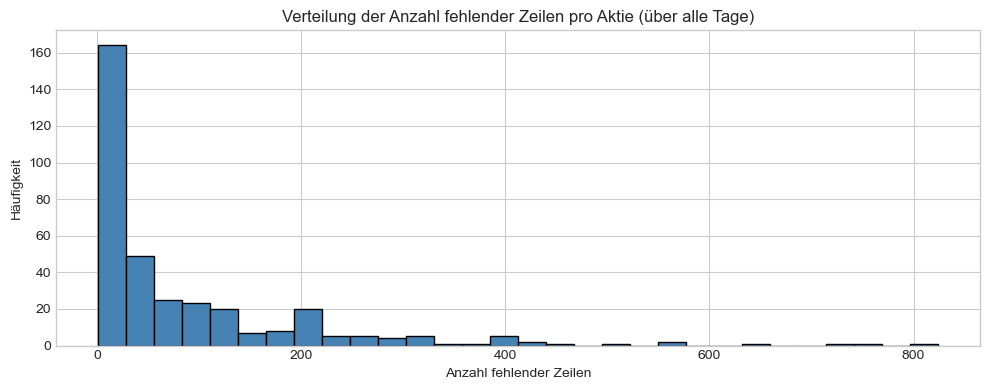

In [28]:
# Sicherstellen: datetime als Datetime, Hilfsspalten
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df = df.sort_values("datetime").reset_index(drop=True)
df["date"] = df["datetime"].dt.date
df["time"] = df["datetime"].dt.time

# Alle Zeilen mit >= 1 NaN in irgendeiner Spalte
is_missing_row = df.isna().any(axis=1)
missing_rows = df[is_missing_row].copy()

# Nach Ticker gruppieren und zählen (über ALLE Tage)
missing_by_symbol = (
    missing_rows.groupby("symbol").size().sort_values(ascending=False)
)

print(f"Es gibt {missing_by_symbol.size} Aktien mit mindestens einem fehlenden Wert.\n")
print("Top 15 betroffene Ticker (mit Anzahl fehlender Zeilen):")
print(missing_by_symbol.head(15))

# Histogramm: Verteilung fehlender Daten nach Aktie (über alle Tage)
plt.figure(figsize=(10,4))
missing_by_symbol.plot(kind="hist", bins=30, color="steelblue", edgecolor="black")
plt.title("Verteilung der Anzahl fehlender Zeilen pro Aktie (über alle Tage)")
plt.xlabel("Anzahl fehlender Zeilen")
plt.ylabel("Häufigkeit")
plt.tight_layout()
plt.show()

# Nach Zeitstempel gruppieren (mehrere Tage!) und zählen
missing_by_timestamp = missing_rows.groupby("datetime").size().rename("count")
missing_time_df = missing_by_timestamp.reset_index()


Nachdem festgestellt wurde, welche Aktien unvollständige Zeitreihen besitzen, wird nun untersucht, **wann** diese Datenlücken im jeweiligen Tagesverlauf auftreten.  
Diese Analyse hilft zu erkennen, ob die fehlenden Werte zufällig verteilt sind oder ob sie zu bestimmten Zeiten des Handelstages gehäuft vorkommen.

Ein gehäuftes Auftreten zu bestimmten Uhrzeiten kann auf **technische Ursachen** (z. B. Marktpause) oder **marktbedingte Phasen geringer Aktivität** hindeuten.  
Insbesondere unmittelbar nach der Marktöffnung und kurz vor Handelsschluss kommt es in hochfrequenten Daten häufig zu Ausreißern oder Lücken.

Zur Analyse wird der Zeitstempel der Daten (`datetime`) extrahiert und auf Minutenebene aggregiert. Anschließend wird gezählt, wie viele Werte zu jedem Zeitpunkt fehlen.  
Das Ergebnis wird in Form eines Liniendiagramms visualisiert, um die Häufigkeit fehlender Werte über den jeweiligen Tag hinweg zu untersuchen.


Tages-Coverage (Zeilen gesamt / Fehlzeilen / Prozent):


,rows_total,rows_missing,missing_%
date,,,
2025-11-07,196667,8838,4.493891
2025-11-10,197057,9906,5.026972
2025-11-11,195887,11633,5.938628


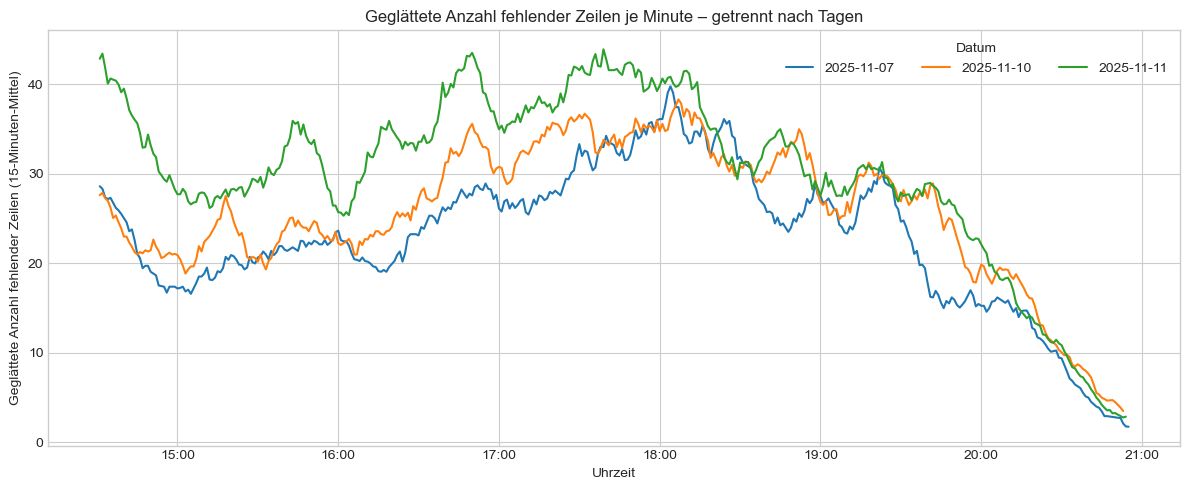

In [ ]:
# Tages-Coverage
daily_rows = df.groupby("date").size().rename("rows_total")
daily_missing = df.isna().any(axis=1).groupby(df["date"]).sum().rename("rows_missing")

coverage = pd.concat([daily_rows, daily_missing], axis=1)
coverage["missing_%"] = 100 * coverage["rows_missing"] / coverage["rows_total"]

print("Tages-Coverage (Zeilen gesamt / Fehlzeilen / Prozent):")
display(coverage.sort_index())

# Fehlwerte über den Tag, getrennt nach Datum
missing_time_by_day = (
    df[df.isna().any(axis=1)]
      .groupby(["date", "time"])
      .size()
      .rename("count")
      .reset_index()
)

# time -> datetime (Dummy-Datum für x-Achse)
missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))

# Glättung (moving average über ~15 Minuten)
# dafür Index als Zeitreihe pro Tag sortieren
smoothed = []
for d, sub in missing_time_by_day.groupby("date"):
    sub = sub.sort_values("time_dt").copy()
    sub["count_smooth"] = sub["count"].rolling(window=15, min_periods=1, center=True).mean()
    smoothed.append(sub)
missing_time_smoothed = pd.concat(smoothed, ignore_index=True)

# Plot: geglättete Kurven
plt.figure(figsize=(12, 5))
for d, sub in missing_time_smoothed.groupby("date"):
    plt.plot(sub["time_dt"], sub["count_smooth"], label=str(d))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.title("Geglättete Anzahl fehlender Zeilen je Minute – getrennt nach Tagen")
plt.xlabel("Uhrzeit")
plt.ylabel("Geglättete Anzahl fehlender Zeilen (15-Minuten-Mittel)")
plt.legend(title="Datum", ncol=min(3, coverage.shape[0]))
plt.tight_layout()
plt.show()


Es ist ein klarer Trend zu erkennenin den fehlenden Daten, jedoch liegt die Erklärung dazu nicht im Rahmen dieses Projekts. Der Trend ist im folgenden Histogramm besser zu erkennen. Das folgende Histogramm visualisiert die durchschnittliche Verteilung der Anzahl fehlender Zeilen über einen Handelstag:
Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte,
einige wenige jedoch deutlich mehr.

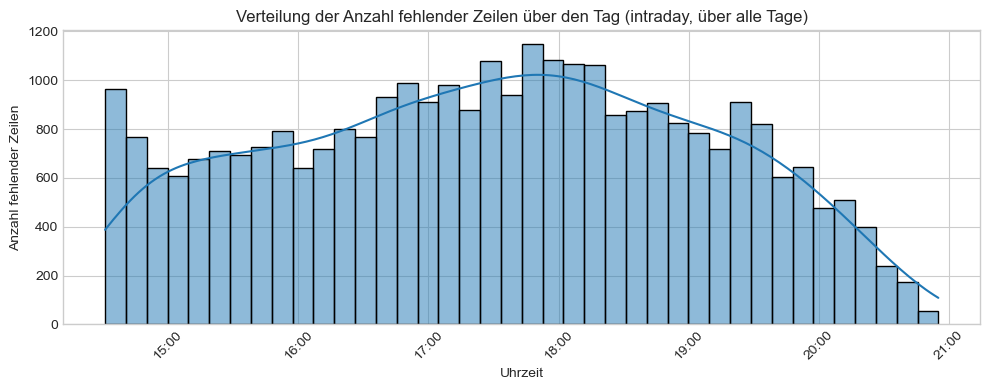

In [ ]:
# Aggregiere fehlende Zeilen pro Zeitstempel (mehrere Tage)
missing_by_timestamp = df[df.isna().any(axis=1)].groupby("datetime").size().rename("count")
missing_time_df = missing_by_timestamp.reset_index()

# Histogramm + KDE über den Tag (wir betrachten Uhrzeit-Komponente)
missing_time_df["time_only"] = missing_time_df["datetime"].dt.time
missing_time_df["time_dt"] = pd.to_datetime(missing_time_df["time_only"].astype(str))

plt.figure(figsize=(10,4))
sns.histplot(
    data=missing_time_df.sort_values("time_dt"),
    x="time_dt",
    weights="count",
    bins=40,
    kde=True
)
plt.title("Verteilung der Anzahl fehlender Zeilen über den Tag (intraday, über alle Tage)")
plt.xlabel("Uhrzeit")
plt.ylabel("Anzahl fehlender Zeilen")
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3.2.3. Datenlücken
Verteilung fehlender Daten über den Tag

- Hier wird mit einem **Histogramm und einer KDE-Kurve** (Dichtekurve) dargestellt,  
  zu welchen Uhrzeiten die meisten fehlenden Daten auftreten.  
- Die X-Achse zeigt die Uhrzeit, die Y-Achse die Anzahl fehlender Zeilen zu diesem Zeitpunkt.  
  Alle Daten stammen von einem einzigen Tag.
- Aus der Grafik lässt sich erkennen, dass fehlende Werte nicht gleichmäßig über den Tag verteilt sind.  
  Besonders am **Nachmittag (zwischen ca. 17:00 und 19:00 Uhr)** treten mehr fehlende Daten auf,  
  während vormittags und spätabends deutlich weniger Lücken vorkommen.

Das deutet darauf hin, dass es zu bestimmten Handelszeiten häufiger Datenlücken gab

Gefundene Lücken insgesamt: 21425



,gap_len,rel_change
count,21425.000000,21425.000000
mean,2.416756,0.000029
std,1.108344,0.001117
min,2.000000,-0.020662
25%,2.000000,-0.000424
50%,2.000000,0.000000
75%,2.000000,0.000494
max,27.000000,0.010461


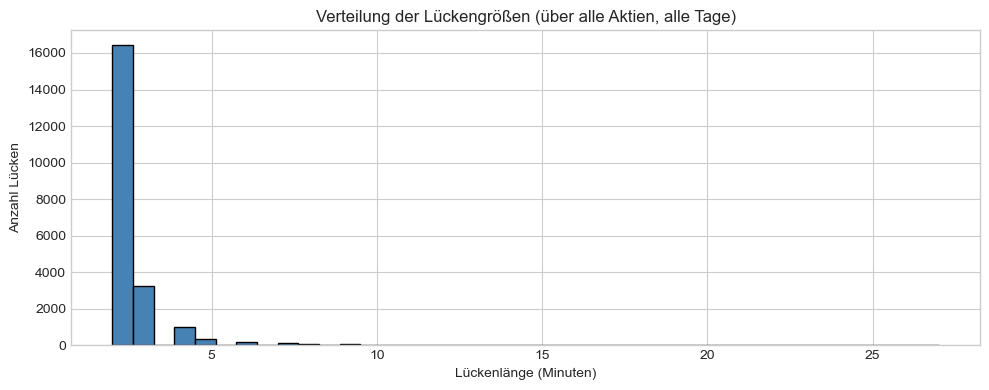

In [7]:
# --- ZELLE 4: Analyse konsekutiver NaN-Lücken (je Aktie, über alle Tage) ---

def analyse_nan_luecken_global(df):
    """
    Findet konsekutive NaN-Blöcke im 'close' je Symbol über den gesamten Datensatz.
    Für jeden Block wird (nahezu) die Lückenlänge in Minuten und die relative
    Preisänderung zwischen dem Wert direkt vor der Lücke und direkt nach der Lücke berechnet.
    """
    normal_step = pd.Timedelta(minutes=1)
    all_gaps = []

    for ticker, data in df.groupby("symbol"):
        data = data.sort_values("datetime").reset_index(drop=True)
        is_nan_close = data["close"].isna()
        if not is_nan_close.any():
            continue

        nan_idx = np.where(is_nan_close)[0]
        gap_blocks = np.split(nan_idx, np.where(np.diff(nan_idx) > 1)[0] + 1)

        for block in gap_blocks:
            # Indizes direkt vor und nach der Lücke
            gap_start_idx = block[0] - 1
            gap_end_idx   = block[-1] + 1
            if gap_start_idx < 0 or gap_end_idx >= len(data):
                continue

            t_before = data.loc[gap_start_idx, "datetime"]
            t_after  = data.loc[gap_end_idx, "datetime"]
            close_before = data.loc[gap_start_idx, "close"]
            close_after  = data.loc[gap_end_idx, "close"]

            # Schutz: angrenzende Werte müssen gültig sein
            if pd.isna(close_before) or pd.isna(close_after):
                continue

            # Lückenlänge anhand der Zeitdifferenz (~ Minuten)
            gap_len = (t_after - t_before) / normal_step
            rel_change = (close_after - close_before) / close_before

            all_gaps.append({
                "symbol": ticker,
                "gap_len": float(gap_len),
                "rel_change": float(rel_change),
            })

    return pd.DataFrame(all_gaps)

# --- Analyse ausführen ---
nan_gaps_all = analyse_nan_luecken_global(df)

print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}\n")
display(nan_gaps_all.describe())

# --- Verteilung der Lückengrößen ---
plt.figure(figsize=(10,4))
plt.hist(nan_gaps_all["gap_len"], bins=40, color="steelblue", edgecolor="black")
plt.title("Verteilung der Lückengrößen (über alle Aktien, alle Tage)")
plt.xlabel("Lückenlänge (Minuten)")
plt.ylabel("Anzahl Lücken")
plt.tight_layout()
plt.show()


**Analyse der NaN-Lücken im Datensatz**

- In dieser Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht.  
  Die Funktion `analyse_nan_luecken_global(df)` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten,  
  berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

- Insgesamt wurden **6 405 Lücken** gefunden.  
  Die statistische Auswertung (`describe()`) zeigt, dass die meisten Lücken kurz sind,
  im Durchschnitt etwa **2,4 Minuten**, mit maximal **27 Minuten**.

- Das Histogramm visualisiert die Verteilung der Lückengrößen:  
  Der Großteil der Lücken beträgt nur 2 Minuten, längere Ausfälle sind sehr selten.  
  Das deutet darauf hin, dass kurze Datenunterbrechungen
  regelmäßig, aber nicht gravierend auftreten.

In [8]:
# --- ZELLE 5: Häufigkeiten pro Lückenlänge ---

# Runde Lückenlänge auf ganze Minuten
nan_gaps_all["gap_len"] = nan_gaps_all["gap_len"].round().astype(int)

gap_counts = nan_gaps_all["gap_len"].value_counts().sort_index()
gap_counts = gap_counts[gap_counts.index >= 0]

print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):\n")
for gap_len, count in gap_counts.items():
    print(f"{gap_len:>4} Minuten : {count}x")


Anzahl vorkommender Lücken pro Lückengröße (in Minuten):

   2 Minuten : 16416x
   3 Minuten : 3216x
   4 Minuten : 989x
   5 Minuten : 361x
   6 Minuten : 164x
   7 Minuten : 98x
   8 Minuten : 62x
   9 Minuten : 44x
  10 Minuten : 21x
  11 Minuten : 13x
  12 Minuten : 15x
  13 Minuten : 4x
  14 Minuten : 3x
  15 Minuten : 5x
  16 Minuten : 1x
  17 Minuten : 5x
  18 Minuten : 2x
  19 Minuten : 1x
  20 Minuten : 1x
  21 Minuten : 1x
  23 Minuten : 1x
  27 Minuten : 2x


**Verteilung der Lückengrößen**

- In diesem Abschnitt wird untersucht, wie häufig bestimmte Längen von Datenlücken im Datensatz vorkommen.  
  Dazu wurden die Lücken in ganze Minuten gerundet und gezählt.  

- Die Ausgabe zeigt, dass die meisten Lücken 2 Minuten lang sind (über 4900 Fälle).  
  Lücken von mehr als 5 Minuten kommen nur sehr selten vor.  


In [9]:
# --- ZELLE 6: Lange Lücken identifizieren ---

long_gaps = nan_gaps_all[nan_gaps_all["gap_len"] > 5]
symbols_with_long_gaps = np.sort(long_gaps["symbol"].unique())

print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(symbols_with_long_gaps)}\n")
print("Aktien mit langen Lücken (> 5 Minuten):")
for sym in symbols_with_long_gaps:
    sub = long_gaps[long_gaps["symbol"] == sym]
    n_luecken = len(sub)
    max_gap = sub["gap_len"].max()
    print(f"  {sym} — {n_luecken} Lücken (max. {int(max_gap)} Minuten)")


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 52

Aktien mit langen Lücken (> 5 Minuten):
  AIZ — 30 Lücken (max. 12 Minuten)
  ALGN — 1 Lücken (max. 7 Minuten)
  ALLE — 4 Lücken (max. 7 Minuten)
  AMP — 1 Lücken (max. 6 Minuten)
  ATO — 1 Lücken (max. 7 Minuten)
  AVY — 11 Lücken (max. 9 Minuten)
  BIIB — 1 Lücken (max. 6 Minuten)
  BR — 2 Lücken (max. 9 Minuten)
  BXP — 2 Lücken (max. 6 Minuten)
  CINF — 18 Lücken (max. 12 Minuten)
  DOV — 1 Lücken (max. 7 Minuten)
  DPZ — 1 Lücken (max. 8 Minuten)
  DRI — 1 Lücken (max. 6 Minuten)
  EME — 3 Lücken (max. 9 Minuten)
  ERIE — 53 Lücken (max. 17 Minuten)
  GL — 7 Lücken (max. 12 Minuten)
  GPC — 3 Lücken (max. 6 Minuten)
  GRMN — 2 Lücken (max. 6 Minuten)
  GWW — 21 Lücken (max. 9 Minuten)
  HWM — 1 Lücken (max. 6 Minuten)
  IDXX — 5 Lücken (max. 8 Minuten)
  IEX — 11 Lücken (max. 19 Minuten)
  IQV — 1 Lücken (max. 7 Minuten)
  J — 3 Lücken (max. 9 Minuten)
  JBL — 1 Lücken (max. 6 Minuten)
  L — 7 Lücken (max. 7 Minuten)
  LDOS

Dieser Codeblock filtert aus der zuvor berechneten Tabelle nan_gaps_all alle Lücken mit einer Länge größer als 5 Minuten heraus und identifiziert die betroffenen Aktien. Anschließend werden die Anzahl betroffener Ticker ausgegeben und für jeden Ticker die Anzahl der langen Lücken sowie die maximale Lückenlänge angezeigt.

Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten (erste 20 Zeilen):

    gap_length_min  n_stocks
0                1       352
1                2       352
2                3       227
3                4       140
4                5        89
5                6        52
6                7        36
7                8        27
8                9        21
9               10        10
10              11         9
11              12         9
12              13         5
13              14         4
14              15         4
15              16         4
16              17         4
17              18         3
18              19         3
19              20         2


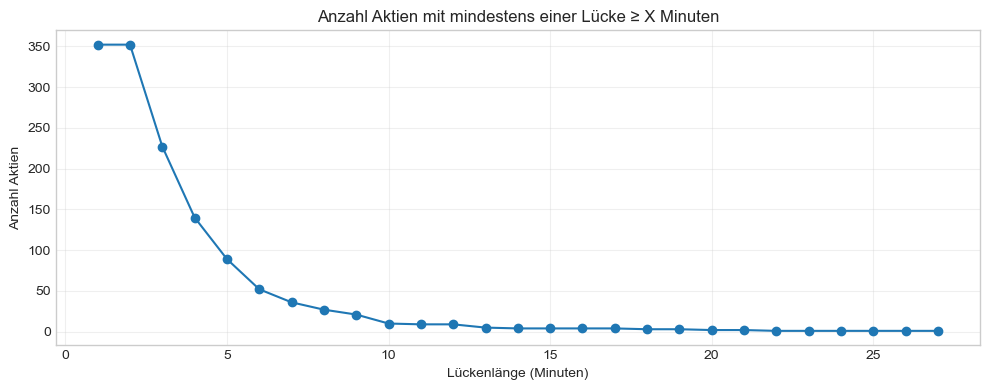

In [10]:
# --- ZELLE 7: Aktienanzahl mit mindestens einer Lücke ≥ X Minuten ---

# (Sicherstellen: ganze Minuten)
nan_gaps_all["gap_len"] = nan_gaps_all["gap_len"].round().astype(int)

max_gap_per_symbol = nan_gaps_all.groupby("symbol")["gap_len"].max()
max_len = int(max_gap_per_symbol.max()) if len(max_gap_per_symbol) else 0

minutes = np.arange(1, max_len + 1) if max_len > 0 else np.array([], dtype=int)
stocks_with_min_gap = [(max_gap_per_symbol >= m).sum() for m in minutes] if minutes.size else []

gap_stats = pd.DataFrame({"gap_length_min": minutes, "n_stocks": stocks_with_min_gap})

print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten (erste 20 Zeilen):\n")
print(gap_stats.head(20))

# Plot (nur wenn es Daten gibt)
if len(gap_stats):
    plt.figure(figsize=(10,4))
    plt.plot(gap_stats["gap_length_min"], gap_stats["n_stocks"], marker="o")
    plt.title("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten")
    plt.xlabel("Lückenlänge (Minuten)")
    plt.ylabel("Anzahl Aktien")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


### 3.2.3. Datenbereinigung


In [ ]:
# maximale Lücke pro Symbol
max_gap_per_symbol = nan_gaps_all.groupby("symbol")["gap_len"].max()

# alle Symbole mit >= 6 Minuten Lücke
symbols_with_long_gaps = max_gap_per_symbol[max_gap_per_symbol >= 6].index
print(f"Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: {len(symbols_with_long_gaps)}")

# Hauptraum säubern: entferne diese Symbole
df_clean = df[~df["symbol"].isin(symbols_with_long_gaps)].copy()
df_clean = df_clean.sort_values("datetime").reset_index(drop=True)

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")
print(f"Zeilen nach Filterung: {len(df_clean):,}")


Anzahl Aktien mit mindestens einer Lücke ≥ 6 Minuten: 52
Verbleibende Aktien nach Filterung: 451
Zeilen nach Filterung: 528,626


In [12]:
# --- ZELLE 9: NaN-Lücken in 'close' auffüllen (pro Aktie) ---

# Sortierung und Typ-Sicherung
df_clean = df_clean.sort_values(["symbol", "datetime"]).copy()
df_clean["datetime"] = pd.to_datetime(df_clean["datetime"], errors="coerce")

def fill_close_gaps(group):
    """
    Interpoliert fehlende Close-Werte (zeitbasiert) und füllt Ränder.
    1. Zeitliche Interpolation für innenliegende NaNs
    2. Vorwärts-/Rückwärtsfüllung für Randbereiche
    """
    group = group.sort_values("datetime").set_index("datetime")
    s = group["close"]

    # Innenliegende Lücken glätten
    s_interp = s.interpolate(method="time", limit_area="inside")

    # Ränder auffüllen
    s_filled = s_interp.bfill().ffill()

    group["close_filled"] = s_filled
    return group.reset_index()

# Auf alle Symbole anwenden
df_filled = df_clean.groupby("symbol", group_keys=False).apply(fill_close_gaps)

# Kontrolle
print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())


Fehlende Werte im Original (gefiltert): 14124
Fehlende Werte in close_filled: 0


In [24]:
# --- ZELLE 10: Längenprüfung pro Symbol ---

print("Analyse der Längen pro Aktie")

# Anzahl Zeilen je Symbol
lengths = df_filled.groupby("symbol").size().sort_values()

print("\nHäufigste Längen:")
print(lengths.value_counts().sort_index())

df_filled.head()

Analyse der Längen pro Aktie

Häufigste Längen:
782       1
1171      2
1172      2
1173    446
dtype: int64


,datetime,symbol,open,high,low,close,volume,date,time,close_filled
0,2025-11-07 14:30:00,A,146.520004,147.119995,145.729996,145.729996,13361.0,2025-11-07,14:30:00,145.729996
1,2025-11-07 14:31:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,14:31:00,145.909996
2,2025-11-07 14:32:00,A,146.089996,146.089996,146.089996,146.089996,427.0,2025-11-07,14:32:00,146.089996
3,2025-11-07 14:33:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,14:33:00,146.069847
4,2025-11-07 14:34:00,A,146.049698,146.049698,146.049698,146.049698,1387.0,2025-11-07,14:34:00,146.049698


In [25]:
# --- ZELLE 11: Erkennung fehlerhafter Symbole (abweichende Längen) ---

print("Erkennung fehlerhafter Symbole anhand abweichender Tageslängen\n")

expected_length = lengths.mode().iloc[0]  # häufigste Länge als Referenz
print(f"Erwartete Anzahl Zeilen pro Symbol: {expected_length}\n")

# Abweichungen finden
bad_symbols = lengths[lengths != expected_length]

if bad_symbols.empty:
    print("Alle Symbole haben die erwartete Länge – keine Entfernung nötig.")
    symbols_to_drop = []
else:
    print(f"{len(bad_symbols)} Symbole mit abweichender Länge gefunden:\n")
    display(bad_symbols)

    # Liste der zu entfernenden Symbole
    symbols_to_drop = bad_symbols.index.tolist()

    print(f"\nZu entfernende Symbole (für Zelle 12):")
    print(symbols_to_drop)


Erkennung fehlerhafter Symbole anhand abweichender Tageslängen

Erwartete Anzahl Zeilen pro Symbol: 1173

5 Symbole mit abweichender Länge gefunden:



symbol
FI       782
DD      1171
CBRE    1171
FICO    1172
TT      1172
dtype: int64


Zu entfernende Symbole (für Zelle 12):
['FI', 'DD', 'CBRE', 'FICO', 'TT']


In [26]:
n_before = df_filled["symbol"].nunique()
df_filled = df_filled[~df_filled["symbol"].isin(symbols_to_drop)].copy()
n_after = df_filled["symbol"].nunique()

print(f"Entfernte Symbole: {symbols_to_drop}")
print(f"Verbleibende Aktien: {n_after} (vorher: {n_before})")

Entfernte Symbole: ['FI', 'DD', 'CBRE', 'FICO', 'TT']
Verbleibende Aktien: 446 (vorher: 451)


### 3.2.4. Fazit Datenqualität


## 3.3. Paarsuche

In [20]:
# Pivot-Tabelle: Zeilen = Zeit, Spalten = Symbol, Werte = Close
price_matrix = df_filled.pivot(index="datetime", columns="symbol", values="close_filled")

# Optional: Logarithmieren (reduziert Trends, stabilisiert Varianz)
log_prices = np.log(price_matrix)

### Ziel und Analyse der Korrelations-Heatmap

Das Hauptziel dieser Analyse war es, **stark korrelierte Aktienpaare** zu identifizieren, also Aktien, deren Kursverläufe sich mit einem sehr hohen linearen Zusammenhang entwickeln (Korrelation r > 0.97).  
Dies ist besonders interessant, um **Muster, Zusammenhänge oder mögliche Arbitragemöglichkeiten** zwischen Aktien zu erkennen.

### Vorgehensweise
1. **Berechnung der Korrelationsmatrix (`corr`)**  
   Alle Aktienpreise wurden paarweise miteinander korreliert, um zu messen, wie ähnlich sich deren Kursbewegungen über den betrachteten Zeitraum verhalten.

2. **Filterung stark korrelierter Paare (r > 0.97)**  
   Nur Aktienpaare mit einem sehr hohen Korrelationswert wurden behalten.  
   → Insgesamt wurden **19 stark korrelierte Aktienpaare** gefunden.

3. **Auswahl der relevantesten Aktien**  
   Aus diesen Paaren wurden die Aktien mit den **höchsten durchschnittlichen Korrelationen** ausgewählt, um die Top-19-Aktien zu bestimmen, die am stärksten miteinander verbunden sind.

4. **Visualisierung als Heatmap**  
   Die resultierende Teilmatrix wurde in einer **Korrelations-Heatmap** dargestellt, wobei:
   - **Rote Felder** = hohe positive Korrelation (ähnliche Kursverläufe)  
   - **Blaue Felder** = geringere oder negative Korrelation  
   - **Weiße Diagonale** = Selbstkorrelation (immer = 1)

### Interpretation der Ergebnisse
- **Hohe Homogenität der Top-Aktien:**  
  Fast alle Aktien innerhalb der Top-19 zeigen **starke positive Korrelationen (>0.75)**, was bedeutet, dass sie sich **ähnlich entwickeln**.  
  Solche Titel reagieren häufig auf **gleiche Marktbedingungen oder Branchentrends**.

- **Clusterbildung:**  
  Es bilden sich Gruppen von Aktien, die besonders stark miteinander korrelieren. Diese Cluster können auf **Sektorzugehörigkeiten** oder **ähnliche Geschäftsmodelle** hinweisen.

- **Starke lineare Beziehungen:**  
  Werte nahe 1 (r ≈ 0.97–0.99) deuten darauf hin, dass zwischen diesen Aktien eine fast **lineare Beziehung** besteht – wenn die eine steigt, steigt die andere mit hoher Wahrscheinlichkeit ebenfalls.



19 stark korrelierte Paare gefunden (r > 0.97)

Min/Max der Off-Diagonal-Korrelationen: 0.7584369938968464 0.9686010927425059


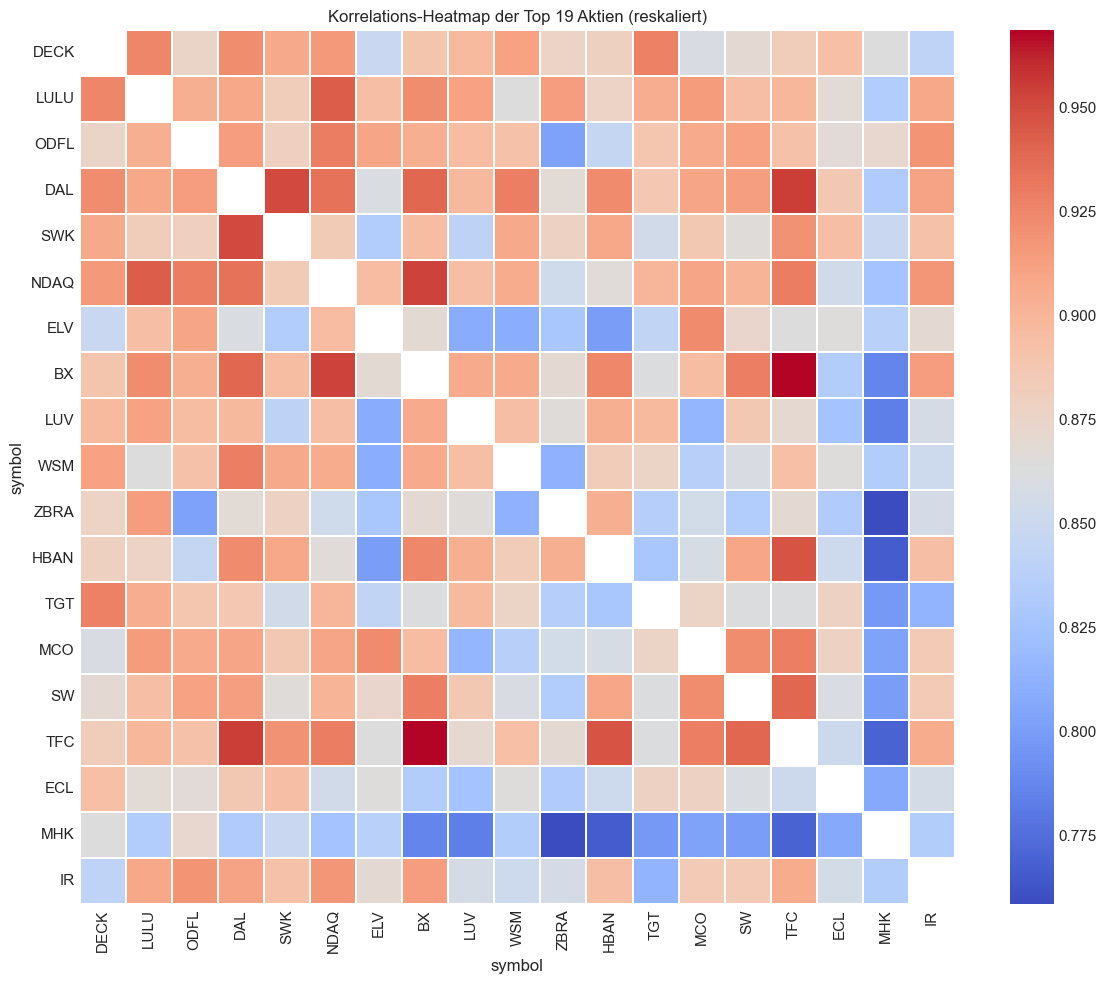

In [21]:
import numpy as np

corr = log_prices.corr()
strong_corr_pairs = [
    (i, j)
    for i in corr.columns
    for j in corr.columns
    if i < j and corr.loc[i, j] > 0.97
]
print(f"{len(strong_corr_pairs)} stark korrelierte Paare gefunden (r > 0.97)")

# Mittelwerte der Korrelationen (um "relevante" Aktien zu finden)
mean_corr = corr.mean().sort_values(ascending=False)

# Top-N Aktien mit höchsten durchschnittlichen Korrelationen
top_n_heatmap = 19
top_symbols = mean_corr.head(top_n_heatmap).index

# Submatrix der Top-N Aktien
corr_sub = corr.loc[top_symbols, top_symbols]

# Diagonale maskieren (1.0-Werte)
mask = np.eye(len(corr_sub), dtype=bool)

# Off-Diagonal-Werte für Min/Max bestimmen
offdiag = corr_sub.where(~pd.DataFrame(mask, index=corr_sub.index, columns=corr_sub.columns))
vmin = offdiag.min().min()
vmax = offdiag.max().max()
print("\nMin/Max der Off-Diagonal-Korrelationen:", vmin, vmax)

# Heatmap mit reskalierter Farbskala
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_sub,
    mask=mask,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=False,
    linewidths=0.2
)
plt.title(f"Korrelations-Heatmap der Top {top_n_heatmap} Aktien (reskaliert)")
plt.tight_layout()
plt.show()

### Ziel und Analyse des Cointegrations-Netzwerks

Das Ziel dieser Analyse ist es, **stark cointegrierte Aktienpaare** zu identifizieren – also Aktien, deren Preisverläufe zwar individuell schwanken, sich aber langfristig **gemeinsam in einem stabilen Gleichgewicht** bewegen.  
Dies ist besonders relevant für **statistische Arbitrage** und **Pair-Trading-Strategien**, da solche Beziehungen auf **langfristig stabile Preisverhältnisse** hinweisen.


### Vorgehensweise
1. **Grundlage: Starke Korrelationen**  
   Aus der vorherigen Analyse wurden Aktienpaare mit hoher Korrelation (r > 0.97) ausgewählt – diese dienen als Ausgangspunkt für den Cointegrationstest.

2. **Engle-Granger-Cointegrationstest**  
   Für jedes dieser Paare wurde der **p-Wert** des Tests berechnet.  
   - Wenn **p < 0.05**, wird die Nullhypothese verworfen, d. h. es besteht **eine signifikante Cointegration**.  
   - Diese Paare wurden in einer Tabelle und anschließend in einem **Netzwerkdiagramm** visualisiert.

3. **Netzwerkdarstellung (Graph)**  
   - **Knoten (Nodes)** = einzelne Aktien  
   - **Kanten (Edges)** = cointegrationsbasierte Verbindungen (p < 0.05) 


### Interpretation der Ergebnisse
- Es wurden **10 signifikante Cointegrationskanten (p < 0.05)** gefunden.  
  Diese Verbindungen zeigen Paare, deren Preisverhältnisse **langfristig stationär** sind – d. h. sie kehren immer wieder zu einem Gleichgewicht zurück.

- **Zentralität der Knoten:**  
  - **PNC**, **IBKR**, und **STT** bilden zentrale Hubs im Netzwerk – sie sind mit mehreren anderen Aktien cointegrativ verbunden.  
  - Dies deutet darauf hin, dass diese Titel **starke gemeinsame Langfristbeziehungen** mit verschiedenen Aktien aufweisen.

- **Beispielhafte Cluster:**
  - **PNC – IBKR – BK – MTB – CFG**: Ein stark verbundenes Cluster, wahrscheinlich aus **Bank- und Finanzwerten**.
  - **FOX – FOXA – STT – NTRS**: Ein weiteres, schwächeres Cluster, möglicherweise durch **ähnliche Marktstrukturen oder Branchenexposition** verbunden.
  - **NVDA – MPWR**: Ein technologiebasiertes Paar mit signifikanter Cointegration (p = 0.044).

### Schlussfolgerungen
1. **Ziel erreicht:**  
   Die Analyse hat **mehrere stark cointegrative Aktienpaare** identifiziert, was auf **langfristig stabile Preisbeziehungen** hindeutet.

2. **Handelsstrategische Relevanz:**  
   - Diese Beziehungen können für **statistische Arbitrage** genutzt werden.  
     Wenn sich die Preisdifferenz zweier cointegrativer Aktien kurzfristig auseinanderbewegt, könnte eine Rückkehr zur Balance (Mean-Reversion) erwartet werden.
   - Damit sind diese Paare potenziell **interessante Kandidaten für Pair-Trading**.

3. **Struktur des Netzwerks:**  
   - Aktien mit vielen Verbindungen (hohem Grad) reagieren tendenziell **ähnlich auf fundamentale oder makroökonomische Einflüsse**.  
   - Isolierte Verbindungen (z. B. NVDA–MPWR) zeigen **spezifische, sektorbasierte Cointegration**, die sich gezielt handeln lässt.


Anzahl Kanten mit p < 0.05: 10


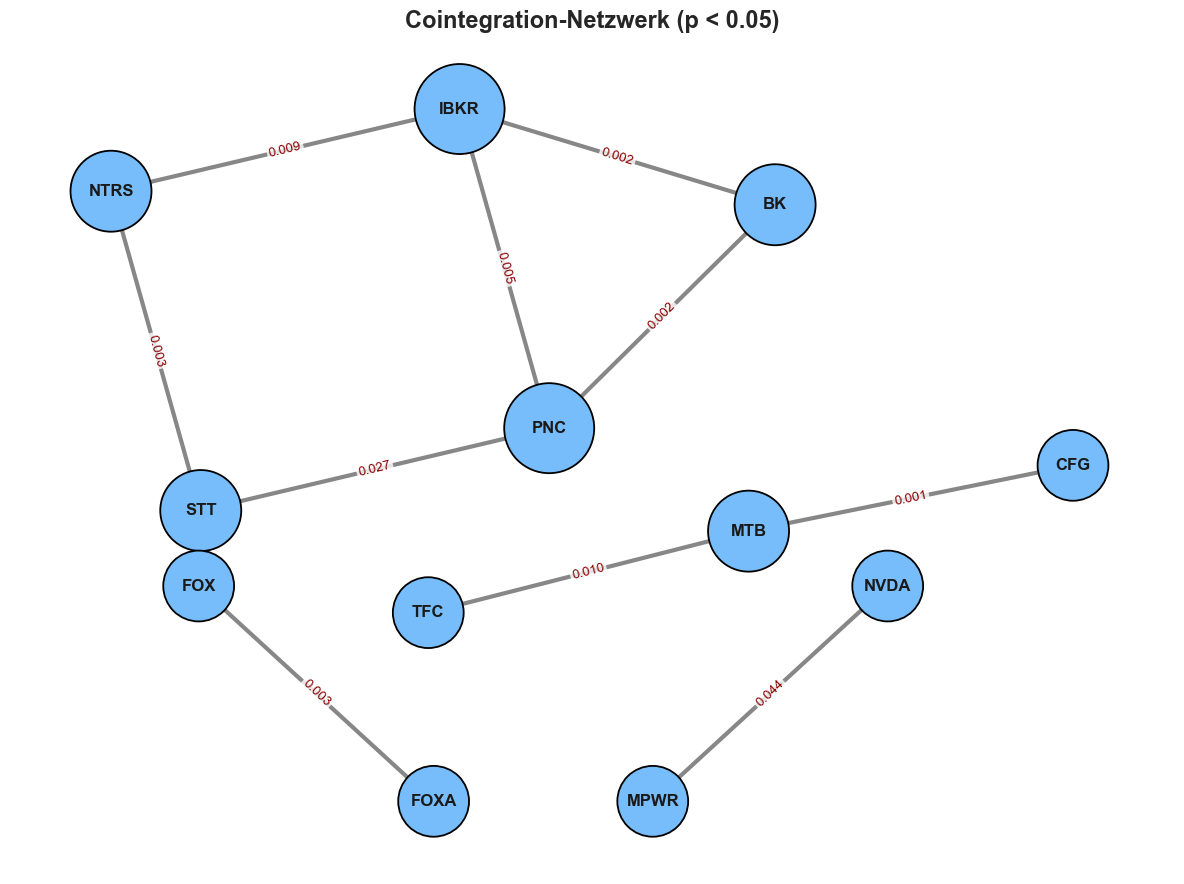

In [22]:
# --- Cointegration wie bisher ---
coint_results = []

for s1, s2 in strong_corr_pairs:
    series1 = log_prices[s1].dropna()
    series2 = log_prices[s2].dropna()
    if len(series1) != len(series2):
        continue

    score, pvalue, _ = coint(series1, series2)
    coint_results.append((s1, s2, pvalue))

coint_df = pd.DataFrame(coint_results, columns=["symbol1", "symbol2", "pvalue"])
coint_df = coint_df.sort_values("pvalue")

# --- Graph aus den Cointegrationspaaren bauen ---

# nur Paare mit "guter" Cointegration nehmen (z.B. p < 0.05)
threshold = 0.05
edges_df = coint_df[coint_df["pvalue"] < threshold]

print(f"Anzahl Kanten mit p < {threshold}: {len(edges_df)}")

G = nx.Graph()

for _, row in edges_df.iterrows():
    s1, s2, pv = row["symbol1"], row["symbol2"], row["pvalue"]
    G.add_edge(s1, s2, pvalue=pv)

if G.number_of_edges() == 0:
    print("Keine Cointegrationspaare unterhalb des p-Schwellenwerts gefunden.")
else:
    plt.figure(figsize=(12, 9))

    # Größere Abstände mit "scale" und mehr Iterationen
    pos = nx.kamada_kawai_layout(G, scale=5.0)  # Standard ist 1.0 → größer = mehr Abstand

    # Knoten deutlich größer und etwas stärker skaliert nach Grad
    degrees = dict(G.degree())
    node_sizes = [1800 + degrees[n] * 800 for n in G.nodes()]

    # Nodes
    nx.draw_networkx_nodes(
        G,
        pos,
        node_color="#77bdfb",
        node_size=node_sizes,
        edgecolors="black",
        linewidths=1.3
    )

    # Edges
    nx.draw_networkx_edges(
        G,
        pos,
        width=3,
        edge_color="#555555",
        alpha=0.7
    )

    # Node-Labels
    nx.draw_networkx_labels(
        G,
        pos,
        font_size=12,
        font_weight="bold"
    )

    # p-Werte als Labels auf den Kanten
    edge_labels = {(u, v): f"{d['pvalue']:.3f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=9.5,
        font_color="darkred",
        label_pos=0.5,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8)
    )

    plt.title(f"Cointegration-Netzwerk (p < {threshold})", fontsize=17, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Ziel und Analyse der normierten Preisverläufe der Top 5 cointegrierten Aktienpaare

Das Ziel dieser Analyse ist es, die **zeitliche Preisentwicklung der am stärksten cointegrierten Aktienpaare** zu visualisieren.  
Durch die Normierung der Preise werden die relativen Bewegungen besser vergleichbar und es lässt sich erkennen, ob sich die Paare langfristig **gemeinsam im Gleichgewicht** bewegen — das zentrale Merkmal von Cointegration.


### Vorgehensweise

1. **Auswahl der Top 5 Cointegrationspaare**  
   Aus der vorherigen Cointegrationsanalyse wurden die fünf Paare mit den **niedrigsten p-Werten (p < 0.05)** ausgewählt.  
   Diese Paare weisen die **stärkste statistische Cointegration** auf.

2. **Exponentielle Transformation und Normierung**  
   - Die logarithmierten Kursdaten wurden exponentiell zurücktransformiert, um wieder Preise zu erhalten.  
   - Danach wurden die Preisreihen **auf denselben Startwert (1.0)** normiert, damit sie direkt vergleichbar sind.

3. **Visualisierung**  
   - Jedes Diagramm zeigt ein Aktienpaar mit seinem zugehörigen **p-Wert**.  
   - Die Linienverläufe zeigen, wie sich beide Aktien **gemeinsam über die Zeit bewegen**.

### Interpretation der Ergebnisse

#### 1. **CFG vs MTB | p = 0.0008**
   - Sehr starke Cointegration.  
   - Beide Aktien verlaufen über weite Strecken nahezu identisch.  
   - Temporäre Abweichungen (z. B. gegen Ende) sind gering und deuten auf eine schnelle Rückkehr zum Gleichgewicht hin.

#### 2. **BK vs IBKR | p = 0.0020**
   - Beide Kurse zeigen eine stabile, parallele Bewegung mit leichter Divergenz in der Mitte.  
   - Typisch für ein Paar, das **mittelfristige Spread-Schwankungen** aufweist, aber **langfristig stabil** bleibt.

#### 3. **BK vs PNC | p = 0.0024**
   - Wieder eine sehr ähnliche Preisentwicklung.  
   - Beide Aktien bewegen sich fast synchron, was die starke Cointegration bestätigt.  
   - Besonders interessant für **Pair-Trading**, da kurzfristige Abweichungen handelbar sein könnten.

#### 4. **NTRS vs STT | p = 0.0030**
   - Nahezu identische Preisverläufe über den gesamten Zeitraum.  
   - Beide Werte reagieren ähnlich auf Marktschwankungen – vermutlich aus demselben Sektor (Banken/Finanzwesen).  
   - Ein klassisches Beispiel für ein **robustes cointegratives Paar**.

#### 5. **FOX vs FOXA | p = 0.0033**
   - Wie zu erwarten, extrem ähnliche Kursbewegungen (beides Aktien derselben Unternehmensgruppe).  
   - Der Spread bleibt eng und stabil – eine **ideale Cointegration**.


### Schlussfolgerungen

1. **Ziel erreicht:**  
   Die Top-5-Paare zeigen alle **starke Cointegration** (p < 0.01), was auf **langfristig stabile Preisverhältnisse** hinweist.

2. **Stabilität und Branchenabhängigkeit:**  
   - Mehrere Paare stammen aus dem **Finanzsektor** (z. B. CFG–MTB, BK–PNC, NTRS–STT), was auf **gemeinsame Marktmechanismen** hinweist.  
   - FOX–FOXA zeigt hingegen eine **strukturelle Verbindung** (gleiche Unternehmensgruppe) – ein Paradebeispiel für perfekte Cointegration.




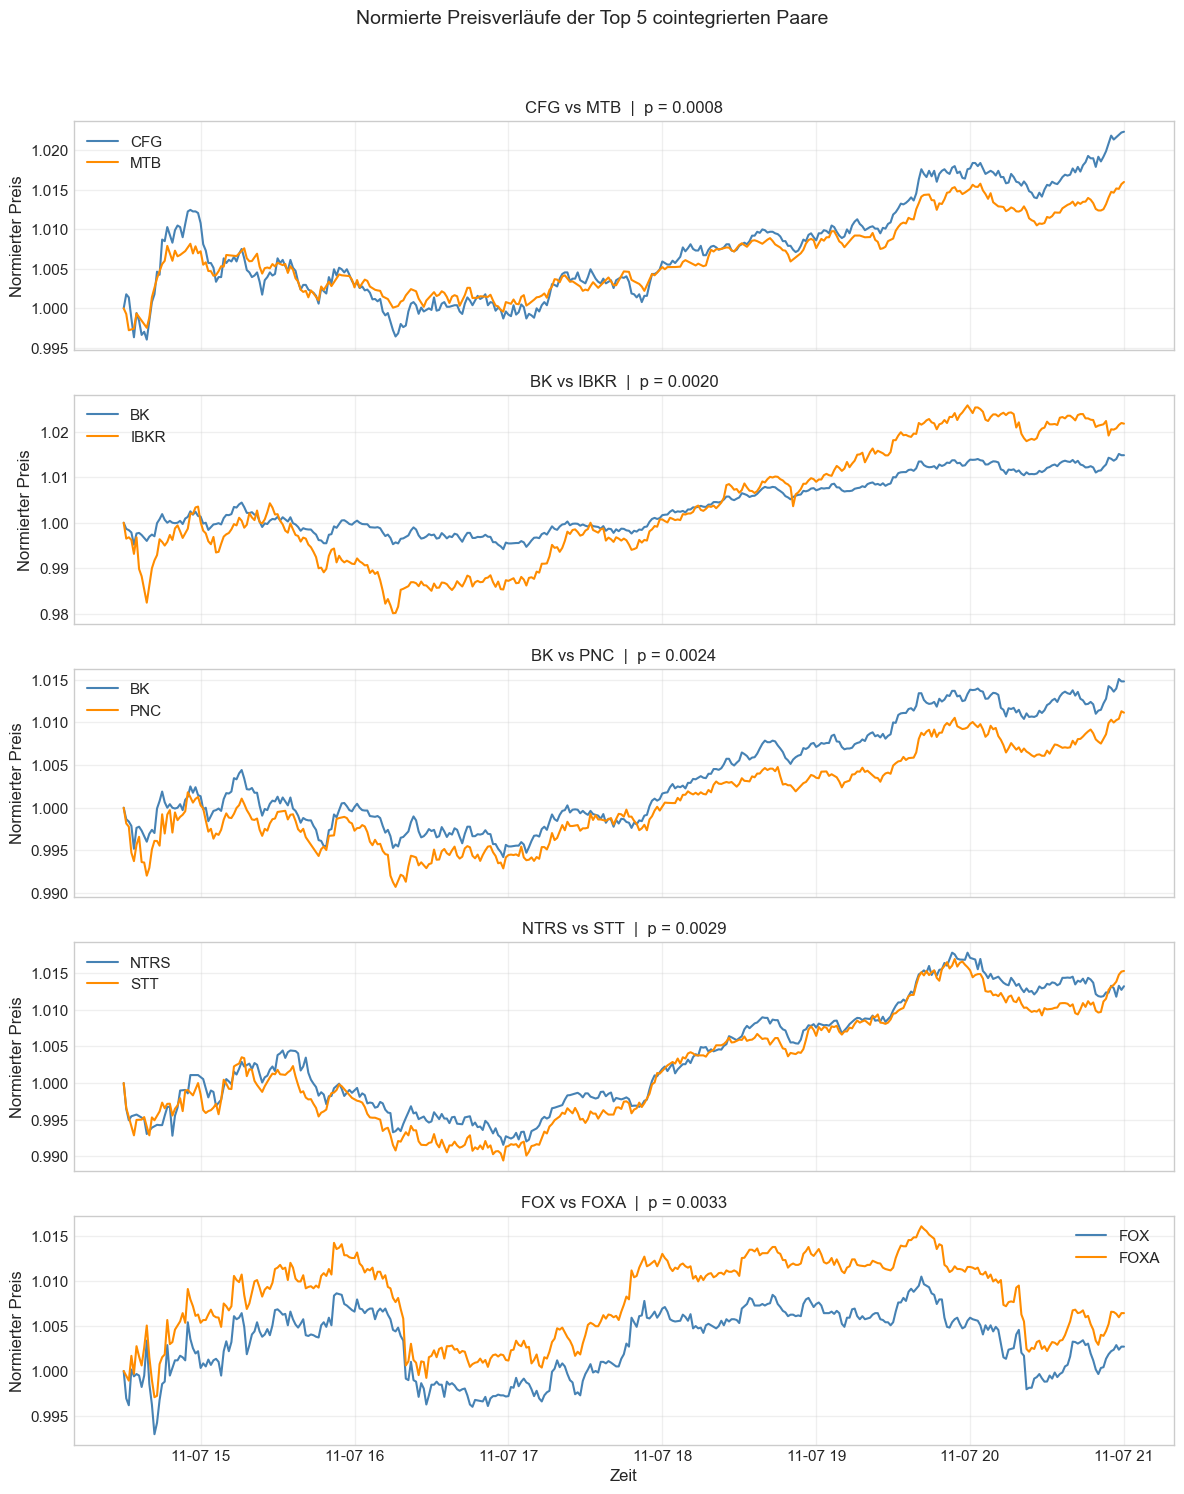

In [23]:
top_n = 5
top_pairs = coint_df.head(top_n)

fig, axes = plt.subplots(top_n, 1, figsize=(12, 3 * top_n), sharex=True)

for idx, (i, row) in enumerate(top_pairs.iterrows()):
    s1, s2, pval = row["symbol1"], row["symbol2"], row["pvalue"]

    # Preisreihen
    p1, p2 = log_prices[s1].copy(), log_prices[s2].copy()

    # Exponentiell zurücktransformieren, um Preise zu bekommen
    p1, p2 = np.exp(p1), np.exp(p2)

    # Normieren auf 1 am Startzeitpunkt
    p1_norm = p1 / p1.iloc[0]
    p2_norm = p2 / p2.iloc[0]

    ax = axes[idx]
    ax.plot(p1_norm, label=s1, color="steelblue")
    ax.plot(p2_norm, label=s2, color="darkorange")
    ax.set_title(f"{s1} vs {s2}  |  p = {pval:.4f}")
    ax.set_ylabel("Normierter Preis")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Zeit")
plt.suptitle("Normierte Preisverläufe der Top 5 cointegrierten Paare", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Ziel und Analyse der Spread-Mean-Reversion bei den Top 5 cointegrierten Aktienpaaren

Das Ziel dieser Analyse ist es, die **stationären Spreads (log-Preis-Differenzen)** der am stärksten cointegrierten Aktienpaare zu untersuchen und deren Verhalten im Verhältnis zu ihrem **langfristigen Mittelwert** zu bewerten.  
Ein **stabiler Spread**, der regelmäßig um einen Mittelwert schwankt, ist ein direktes Zeichen für **Cointegration** und somit für **Mean-Reversion-Potenzial**.


### Vorgehensweise

**Berechnung des Spreads:**  
   Der Spread zwischen zwei Aktien wurde berechnet als:  
  {Spread}(t) = \log(P_1(t)) - \log(P_2(t))  
   Dadurch wird der Preisunterschied in Prozent-ähnliche Einheiten transformiert, was Vergleiche zwischen Aktien mit unterschiedlichen Preisniveaus ermöglicht.

 **Bestimmung des Mittelwerts:**  
   Für jede Paarzeitreihe wurde der **durchschnittliche Spread** berechnet und als **rote gestrichelte Linie** eingezeichnet.  
   Dieser Mittelwert repräsentiert das **langfristige Gleichgewichtsniveau** zwischen den beiden Aktien.

**Visualisierung:**  
   - **Blaue Linie:** Zeitlicher Verlauf des Spreads (log-Preis-Differenz)  
   - **Rote Linie:** Mittelwert (Gleichgewicht)  
   - **p-Wert:** Signifikanz der Cointegration (je kleiner, desto stärker die Beziehung)


### Interpretation der Ergebnisse

#### **1. CFG vs MTB | p = 0.0008**
   - Der Spread schwankt eng um den Mittelwert (-1.2848).  
   - Deutliche Rückkehrbewegungen nach Ausschlägen: **Mean-Reversion-Effekt**.  
   - Stark cointegriertes Paar, ideal für **statistische Arbitrage**.

#### **2. BK vs IBKR | p = 0.0020**
   - Langsam abnehmender Spread mit sichtbarer Rückkehr zum Mittelwert in der Mitte des Zeitraums.  
   - Zeigt **langfristige Stabilität**, trotz temporärer Trendbewegung.  
   - Moderate, aber signifikante Cointegration.

#### **3. BK vs PNC | p = 0.0024**
   - Spread oszilliert regelmäßig um den Mittelwert (-0.5197).  
   - Gute Balance zwischen Schwankung und Rückkehrbewegung.  
   - Typisches Verhalten für **gleichartige Finanzwerte** mit strukturellem Gleichgewicht.

#### **4. NTRS vs STT | p = 0.0030**
   - Beide Aktien bewegen sich in einem **engen, stationären Spreadbereich** (0.09–0.10).  
   - Zeigt häufige Rückkehrbewegungen: **Mean-Reversion-Effekt**.  
   - Solider Kandidat für Pair-Trading im Bankensektor.

#### **5. FOX vs FOXA | p = 0.0033**
   - Sehr enger Spread um -0.1046, nahezu konstant über den Zeitraum.  
   - Minimaler Trend und klare Rückkehr zum Mittelwert.  


### Schlussfolgerungen

1. **Ziel erreicht:**  
   Die Visualisierung zeigt, dass alle Paare um einen stabilen Mittelwert schwanken.
2. **Handelsrelevanz:**  
   - Wenn der Spread **oberhalb des Mittelwerts** liegt → Aktie 1 ist relativ **überbewertet**, Aktie 2 **unterbewertet**.  
   - Wenn der Spread **unterhalb des Mittelwerts** liegt → umgekehrte Positionierung.



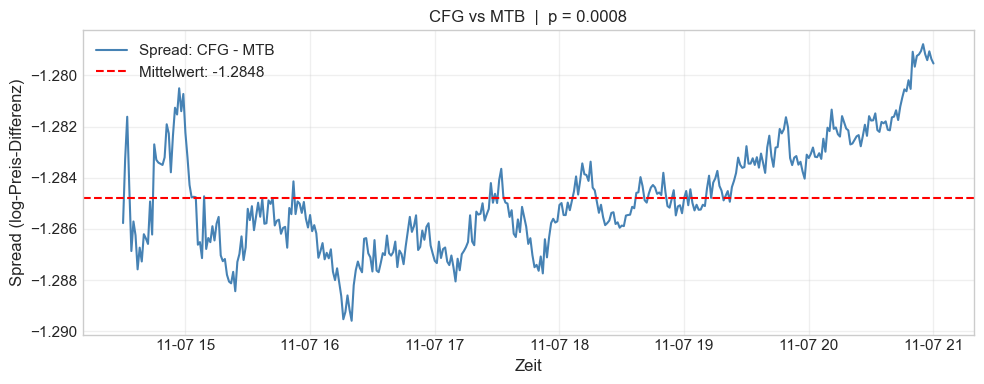

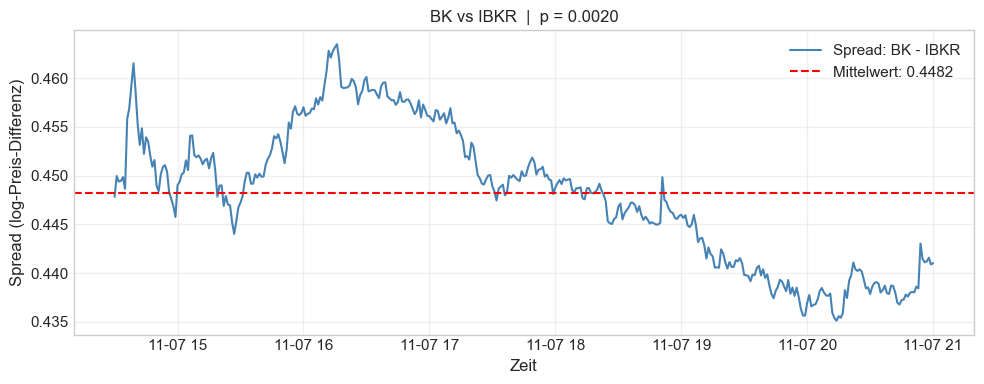

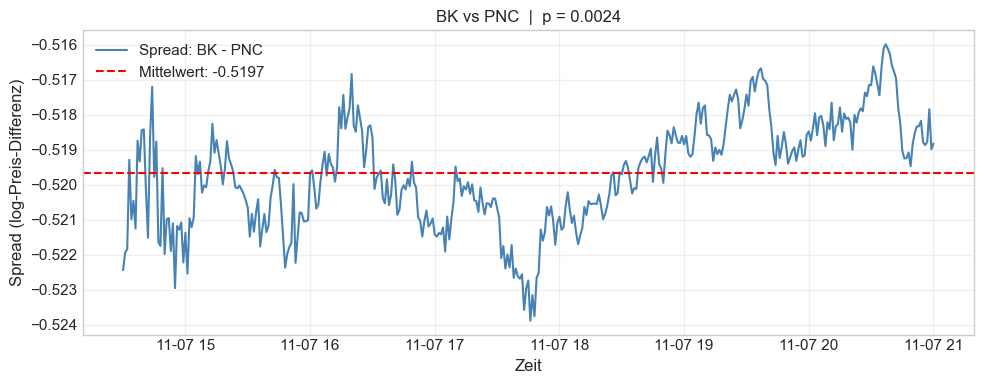

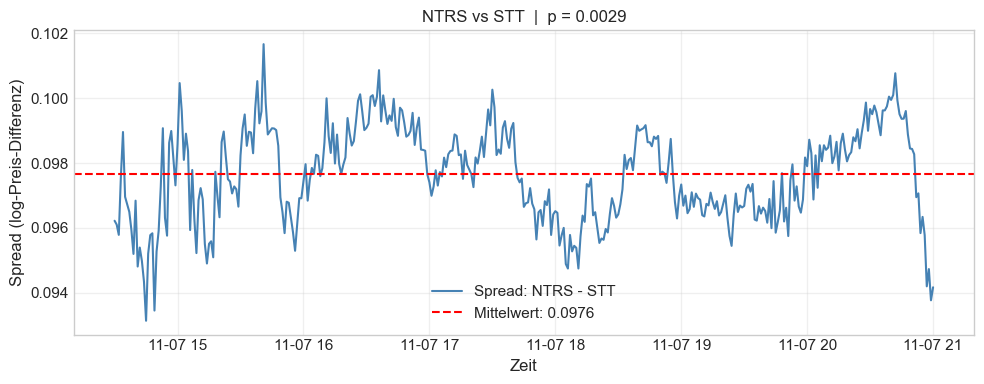

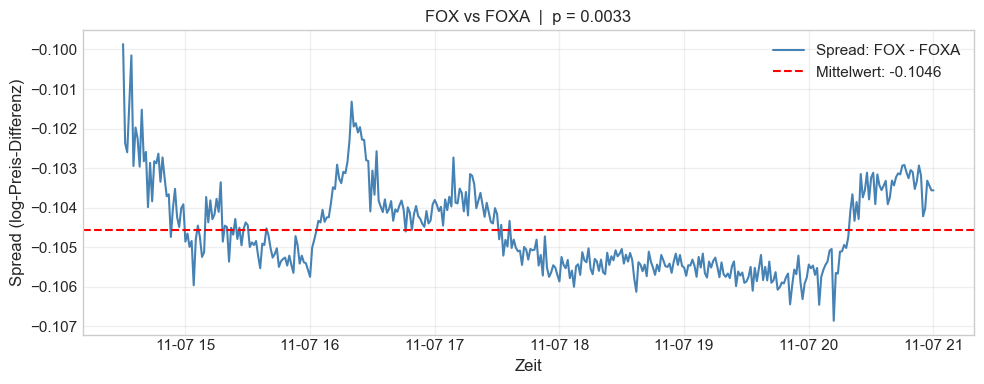

In [24]:
top_pairs = coint_df.head(top_n)

for i, row in top_pairs.iterrows():
    s1, s2, pval = row["symbol1"], row["symbol2"], row["pvalue"]
    spread = log_prices[s1] - log_prices[s2]
    mean_spread = spread.mean()  # Mittelwert berechnen

    plt.figure(figsize=(10, 4))
    plt.plot(spread, label=f"Spread: {s1} - {s2}", color='steelblue')
    plt.axhline(y=mean_spread, color='red', linestyle='--', 
                label=f'Mittelwert: {mean_spread:.4f}')
    
    plt.title(f"{s1} vs {s2}  |  p = {pval:.4f}")
    plt.xlabel("Zeit")
    plt.ylabel("Spread (log-Preis-Differenz)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datensammlung.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
